In [5]:
import numpy as np

pop_cols = sorted(c for c in df.columns if c.startswith("gh_pop_tot_"))
print("Столбцы gh_pop_tot:", pop_cols)

rows = []
for c in pop_cols:
    s = df[c]
    rows.append({
        "column": c,
        "dtype": str(s.dtype),
        "non_null": int(s.notna().sum()),
        "zeros": int((s == 0).sum()),
        "min": float(s.min()),
        "q1": float(s.quantile(0.25)),
        "median": float(s.median()),
        "mean": round(float(s.mean()), 1),
        "q3": float(s.quantile(0.75)),
        "max": float(s.max()),
    })
print("\n", pd.DataFrame(rows).to_string(index=False))

# сверка с gc_pop_tot_2025 (одно и то же население или нет)
for c in ("gh_pop_tot_2025", "gc_pop_tot_2025"):
    if c in df.columns:
        print(c, "медиана:", float(df[c].median()), "сумма:", float(df[c].sum()))
both = [c for c in ("gh_pop_tot_2025", "gc_pop_tot_2025") if c in df.columns]
if len(both) == 2:
    diff = (df[both[0]] - df[both[1]]).abs()
    print("макс. расхождение gh vs gc 2025:", float(diff.max()),
          "| доля строк с расхождением > 1:", round(float((diff > 1).mean()), 3))

# словарь для gh_pop_tot
print("\n", dic[dic["column"].str.startswith("gh_pop_tot_")][["column", "indicator", "unit", "sheet"]].to_string(index=False))

# группы: кандидаты и число значений
for g in ("gc_dev_wig_2025", "gc_cnt_gad_2025"):
    print("\n", g, "\n", df[g].value_counts(dropna=False).head(8).to_string())

Столбцы gh_pop_tot: ['gh_pop_tot_1975', 'gh_pop_tot_1980', 'gh_pop_tot_1985', 'gh_pop_tot_1990', 'gh_pop_tot_1995', 'gh_pop_tot_2000', 'gh_pop_tot_2005', 'gh_pop_tot_2010', 'gh_pop_tot_2015', 'gh_pop_tot_2020', 'gh_pop_tot_2025', 'gh_pop_tot_2030']

          column   dtype  non_null  zeros          min          q1       median     mean           q3         max
gh_pop_tot_1975 float64      1089      0     0.991446 29646.92738  44852.92725 148566.0  85351.51321 11477377.14
gh_pop_tot_1980 float64      1089      0     3.083040 33366.98909  50073.01947 172912.5  98637.05712 13665064.16
gh_pop_tot_1985 float64      1089      0    10.282825 36827.40322  55956.90282 194262.1 114065.19720 14682401.12
gh_pop_tot_1990 float64      1089      0    36.182027 40224.02497  61786.62916 217710.9 130485.83950 15757807.59
gh_pop_tot_1995 float64      1089      0   132.662389 45771.75146  69212.80807 240418.6 145356.57300 16780193.11
gh_pop_tot_2000 float64      1089      0   485.292967 50197.88804  7585

In [7]:
import importlib
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))

from src import eda

importlib.reload(eda)

df = eda.read_clean(Path("..") / "data" / "processed" / "clean.parquet")
long = eda.to_long(df)
print(long.shape, long.dtypes.astype(str).to_dict())
print("пропуски:", long.isna().sum().to_dict())

print("\n", eda.period_table(long).to_string(index=False))

cross = long[long[eda.DATE] == 2025]
print("\n", eda.describe_target(cross[eda.TARGET]))

counts = cross[eda.GROUP].value_counts()
rare = counts[counts / counts.sum() < eda.RARE_SHARE]
print("\nСтран:", len(counts), "| редких (< 1 %):", len(rare), "| городов в них:", int(rare.sum()))
print(counts.to_string())

(13068, 4) {'id_uc_g0': 'int64', 'country': 'category', 'year': 'int16', 'pop_tot': 'float64'}
пропуски: {'id_uc_g0': 0, 'country': 0, 'year': 0, 'pop_tot': 0}

  year    n       median          mean
 1975 1089  44852.92725 148565.990080
 1980 1089  50073.01947 172912.533142
 1985 1089  55956.90282 194262.100734
 1990 1089  61786.62916 217710.872659
 1995 1089  69212.80807 240418.640299
 2000 1089  75854.07177 263155.026459
 2005 1089  82994.08443 281765.747257
 2010 1089  89457.77671 299689.792608
 2015 1089  96458.47632 317236.572175
 2020 1089 102000.62510 327660.155730
 2025 1089 106085.50230 338277.903551
 2030 1089 108435.69860 348480.522006

 {'Число наблюдений': 1089, 'Число пропусков': 0, 'Минимум': 50039.9198, 'Первый квартиль': 67195.63277, 'Медиана': 106085.5023, 'Среднее': 338277.9035511019, 'Третий квартиль': 218648.9798, 'Максимум': 19485157.73, 'Скошенность': 'вправо'}

Стран: 32 | редких (< 1 %): 17 | городов в них: 59
country
Brazil                 366
México         

In [9]:
import importlib
import logging

import numpy as np

Path("..", "logs").mkdir(exist_ok=True)
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s %(message)s",
    handlers=[logging.FileHandler(Path("..") / "logs" / "eda.log", encoding="utf-8"),
              logging.StreamHandler()],
    force=True,
)

importlib.reload(eda)
cross = long[long[eda.DATE] == 2025].reset_index(drop=True)

rare = eda.rare_groups(cross)
print("редких:", len(rare), "| слито городов:", int(cross[eda.GROUP].isin(rare).sum()))

print("\nТаблица 3 (первые 8 строк и редкие):")
t3 = eda.group_table(cross)
print(t3.head(8).to_string(index=False))
print(t3.tail(3).to_string(index=False))

pivot = eda.pivot_median(eda.collapse_rare(long, rare))
print("\nСводная:", pivot.shape, "| пустых ячеек:", int(pivot.isna().sum().sum()))

t4, mask_iqr, mask_z = eda.anomaly_report(cross[eda.TARGET])
print("\n", t4.to_string(index=False))

top = cross.loc[mask_iqr].nlargest(5, eda.TARGET)[[eda.ID_COL, eda.GROUP, eda.TARGET]]
print("\nТоп-5 по численности среди отмеченных IQR:\n", top.to_string(index=False))

print("\nТаблица 5:")
print(eda.benchmark_mean(long[eda.TARGET].to_numpy()).to_string(index=False))

2026-11-03 16:09:44,168 всего строк: 1089
2026-11-03 16:09:44,169 IQR отметил: 130
2026-11-03 16:09:44,169 |z| > 3 отметил: 12
2026-11-03 16:09:44,169 в обоих списках: 12


редких: 17 | слито городов: 59

Таблица 3 (первые 8 строк и редкие):
  country   n        median          mean  nan_share
   Brazil 366  94540.163045 329892.823413        0.0
   México 182 118456.460650 387356.600250        0.0
 Colombia  83 119466.168400 400512.801265        0.0
Argentina  77  90301.947580 386807.192484        0.0
Venezuela  70 122056.323900 267703.047767        0.0
     Peru  43 118109.693400 453164.796934        0.0
    Chile  38 123292.308750 338565.450197        0.0
  Ecuador  34  95994.864475 304765.036132        0.0
   country  n       median         mean  nan_share
   Bahamas  1 261235.20510 261235.20510        0.0
Martinique  1  91150.17104  91150.17104        0.0
  Suriname  1 253625.51110 253625.51110        0.0

Сводная: (16, 12) | пустых ячеек: 0

               Правило  Число отмеченных     Доля  Совпало со вторым
Межквартильный размах               130 0.119376                 12
              |z| > 3                12 0.011019                 12
       

In [10]:
import importlib
import logging
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("..").resolve()))

from src import eda

importlib.reload(eda)

(Path("..") / "logs").mkdir(exist_ok=True)
PLOTS = Path("..") / "plots"
PLOTS.mkdir(exist_ok=True)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s %(message)s",
    handlers=[
        logging.FileHandler(Path("..") / "logs" / "eda.log", encoding="utf-8"),
        logging.StreamHandler(),
    ],
    force=True,
)

df = eda.read_clean(Path("..") / "data" / "processed" / "clean.parquet")
long = eda.to_long(df)
cross = long[long[eda.DATE] == 2025].reset_index(drop=True)
rare = eda.rare_groups(cross)
print("long:", long.shape, "| срез 2025:", cross.shape, "| редких групп:", len(rare))

long: (13068, 4) | срез 2025: (1089, 4) | редких групп: 17


In [11]:
for line in (Path("..") / "DATASET.md").read_text(encoding="utf-8").splitlines():
    if any(word in line.lower() for word in ("2030", "projection", "прогноз", "модел")):
        print(line[:300])

**Правила аномалий (названы до рисунков).** Правило 1: межквартильный размах, граница Q1 − 1,5·IQR и Q3 + 1,5·IQR, на исходной шкале, срез 2025. Правило 2: |z| > 3, тот же срез. Пороги не подбирались по рисункам. Строки `clean.parquet` не удаляются, маска живёт только в расчёте.

In [12]:
t4, mask_iqr, mask_z = eda.anomaly_report(cross[eda.TARGET])
print(t4.to_string(index=False))

2026-11-08 18:22:16,382 всего строк: 1089
2026-11-08 18:22:16,383 IQR отметил: 130
2026-11-08 18:22:16,383 |z| > 3 отметил: 12
2026-11-08 18:22:16,383 в обоих списках: 12


              Правило  Число отмеченных     Доля  Совпало со вторым
Межквартильный размах               130 0.119376                 12
              |z| > 3                12 0.011019                 12
          Пересечение                12 0.011019                 12


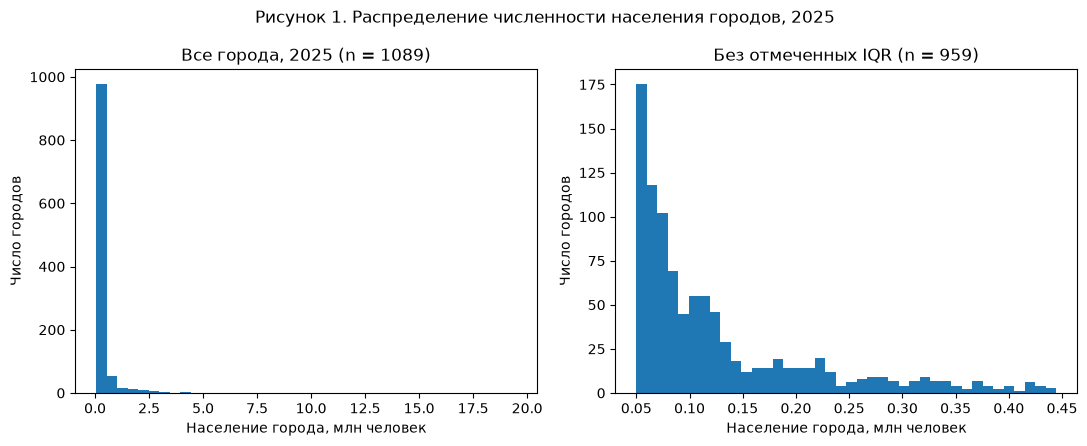

In [13]:
import matplotlib.pyplot as plt

values = cross[eda.TARGET].to_numpy() / 1e6
inside = cross.loc[~mask_iqr, eda.TARGET].to_numpy() / 1e6

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].hist(values, bins=40)
axes[0].set_title(f"Все города, 2025 (n = {len(values)})")
axes[1].hist(inside, bins=40)
axes[1].set_title(f"Без отмеченных IQR (n = {len(inside)})")
for ax in axes:
    ax.set_xlabel("Население города, млн человек")
    ax.set_ylabel("Число городов")
fig.suptitle("Рисунок 1. Распределение численности населения городов, 2025")
fig.tight_layout()
fig.savefig(PLOTS / "01_hist.png", dpi=150)
plt.show()

**Наблюдение 1.** В 2025 году медиана населения города 106 тыс. человек, среднее 338 тыс., то есть в 3,2 раза выше. Распределение скошено вправо: 130 из 1089 городов (11,9 %) лежат выше правой границы IQR, максимум 19,5 млн (Бразилия).

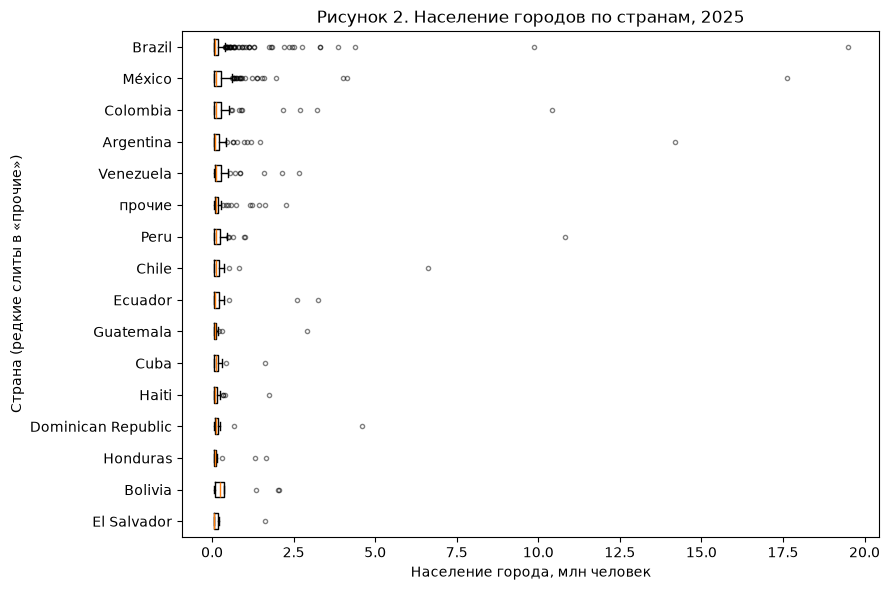

In [16]:
merged = eda.collapse_rare(cross, rare)
order = eda.group_table(merged)["country"].tolist()
data = [merged.loc[merged[eda.GROUP] == name, eda.TARGET].to_numpy() / 1e6 for name in order]

fig, ax = plt.subplots(figsize=(9, 6))
ax.boxplot(data, orientation="horizontal", tick_labels=order, flierprops={"markersize": 3, "alpha": 0.5})
ax.invert_yaxis()
ax.set_xlabel("Население города, млн человек")
ax.set_ylabel("Страна (редкие слиты в «прочие»)")
ax.set_title("Рисунок 2. Население городов по странам, 2025")
fig.tight_layout()
fig.savefig(PLOTS / "02_by_country.png", dpi=150)
plt.show()

**Наблюдение 2.** Медиана населения города в Бразилии (94,5 тыс.) ниже, чем в Чили (123,3 тыс.), Венесуэле (122,1 тыс.) и Колумбии (119,5 тыс.), хотя в Бразилии больше всего городов (366) и именно там максимум набора, 19,5 млн.

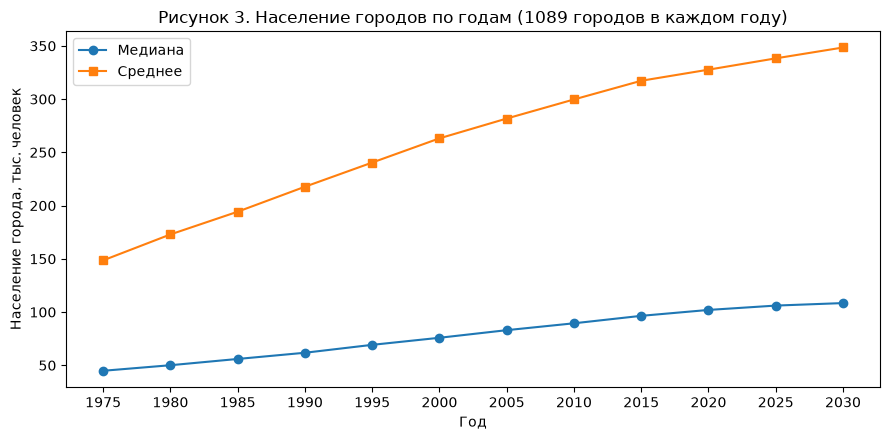

In [17]:
series = eda.period_table(long)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(series[eda.DATE], series["median"] / 1e3, marker="o", label="Медиана")
ax.plot(series[eda.DATE], series["mean"] / 1e3, marker="s", label="Среднее")
ax.set_xticks(series[eda.DATE])
ax.set_xlabel("Год")
ax.set_ylabel("Население города, тыс. человек")
ax.set_title("Рисунок 3. Население городов по годам (1089 городов в каждом году)")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "03_series.png", dpi=150)
plt.show()

**Наблюдение 3.** Медиана выросла с 44,9 тыс. (1975) до 108,4 тыс. (2030), в 2,4 раза, но рост замедляется: +11,6 % за 1975–1980, +4,0 % за 2020–2025 и +2,2 % за 2025–2030. Пустых периодов нет, в каждом году 1089 записей, поэтому изменение числа записей ряд не объясняет.

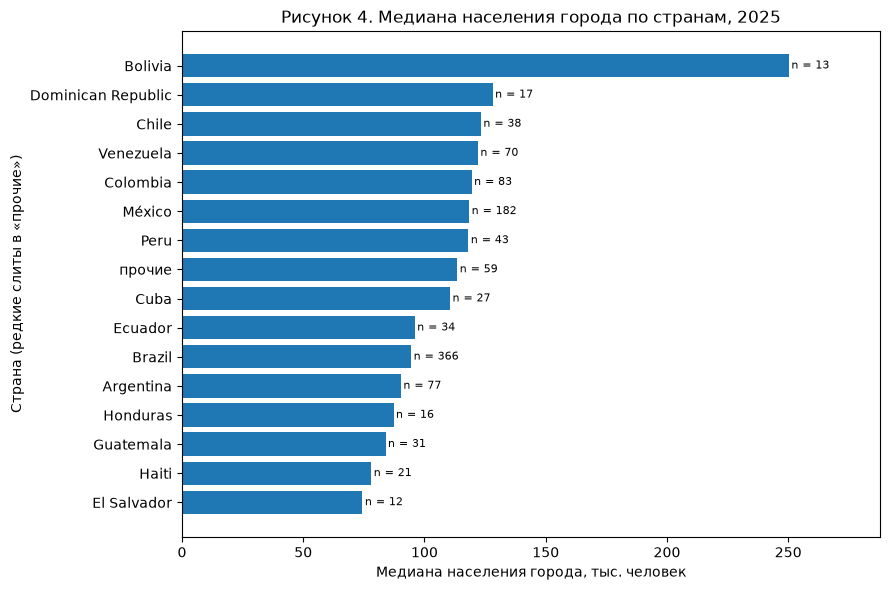

           country   n   median
           Bolivia  13 250298.0
Dominican Republic  17 128131.0
             Chile  38 123292.0
         Venezuela  70 122056.0
          Colombia  83 119466.0
            México 182 118456.0
              Peru  43 118110.0
            прочие  59 113538.0
              Cuba  27 110568.0
           Ecuador  34  95995.0
            Brazil 366  94540.0
         Argentina  77  90302.0
          Honduras  16  87250.0
         Guatemala  31  83933.0
             Haiti  21  78081.0
       El Salvador  12  74438.0


In [18]:
merged = eda.collapse_rare(cross, rare)
t3m = eda.group_table(merged).sort_values("median", ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(t3m["country"], t3m["median"] / 1e3)
ax.invert_yaxis()
for i, (med, n) in enumerate(zip(t3m["median"], t3m["n"])):
    ax.text(med / 1e3 + 1, i, f"n = {n}", va="center", fontsize=8)
ax.set_xlim(0, t3m["median"].max() / 1e3 * 1.15)
ax.set_xlabel("Медиана населения города, тыс. человек")
ax.set_ylabel("Страна (редкие слиты в «прочие»)")
ax.set_title("Рисунок 4. Медиана населения города по странам, 2025")
fig.tight_layout()
fig.savefig(PLOTS / "04_median_by_country.png", dpi=150)
plt.show()

print(t3m[["country", "n", "median"]].round(0).to_string(index=False))

**Наблюдение 4.** Медиана населения города в Боливии 250,3 тыс. человек при 13 городах, то есть почти вдвое выше следующей по списку Доминиканской Республики (128,1 тыс., 17 городов). Бразилия с 366 городами имеет медиану 94,5 тыс., а у Сальвадора (12 городов) она самая низкая, 74,4 тыс.

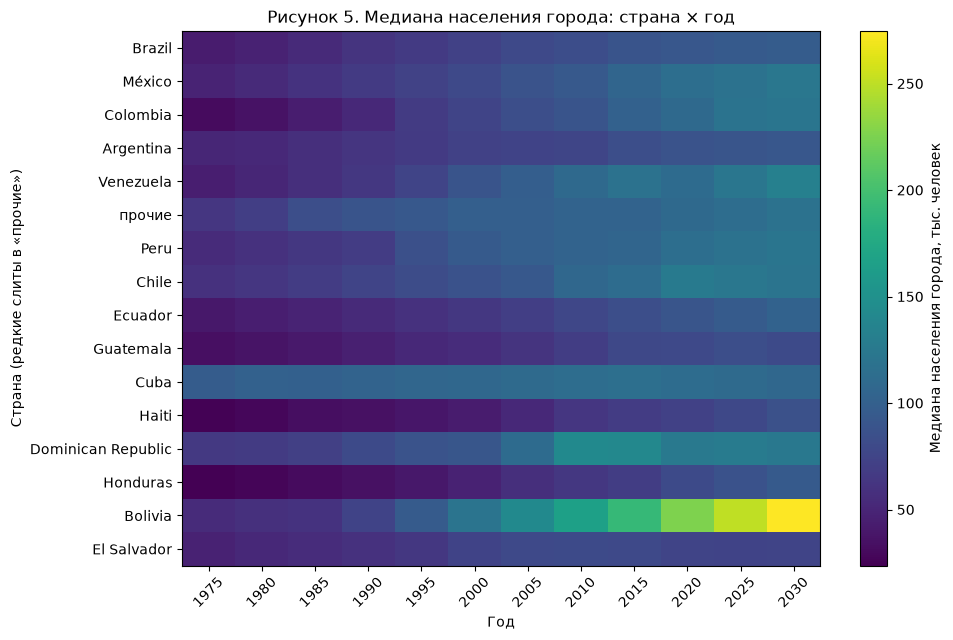

Пустых ячеек: 0
2025: максимум Bolivia 250.3 | минимум El Salvador 74.4
country
Cuba                  1.11
El Salvador           1.56
Argentina             1.81
прочие                1.87
Dominican Republic    1.89
Chile                 2.03
Peru                  2.22
Brazil                2.28
Guatemala             2.36
México                2.54
Ecuador               2.59
Venezuela             2.93
Haiti                 3.46
Colombia              3.85
Honduras              4.01
Bolivia               5.01


In [19]:
pivot = eda.pivot_median(eda.collapse_rare(long, rare)) / 1e3
pivot = pivot.reindex(eda.group_table(merged)["country"])

fig, ax = plt.subplots(figsize=(10, 6.5))
image = ax.imshow(pivot.to_numpy(), aspect="auto", cmap="viridis")
ax.set_xticks(range(pivot.shape[1]))
ax.set_xticklabels(pivot.columns, rotation=45)
ax.set_yticks(range(pivot.shape[0]))
ax.set_yticklabels(pivot.index)
ax.set_xlabel("Год")
ax.set_ylabel("Страна (редкие слиты в «прочие»)")
ax.set_title("Рисунок 5. Медиана населения города: страна × год")
fig.colorbar(image, ax=ax, label="Медиана населения города, тыс. человек")
fig.tight_layout()
fig.savefig(PLOTS / "05_heatmap.png", dpi=150)
plt.show()

print("Пустых ячеек:", int(pivot.isna().sum().sum()))
print("2025: максимум", pivot[2025].idxmax(), round(float(pivot[2025].max()), 1),
      "| минимум", pivot[2025].idxmin(), round(float(pivot[2025].min()), 1))
print((pivot[2030] / pivot[1975]).sort_values().round(2).to_string())

**Наблюдение 5.** Пустых ячеек нет: все 16 групп представлены во всех 12 годах. Строка Боливии темнеет до 1990 года и светлеет к жёлтому после 1995, в 2025 году она максимальная (250,3 тыс.), а строка Кубы почти ровная (2030 к 1975: в 1,11 раза). Минимум 2025 года у Сальвадора, 74,4 тыс.

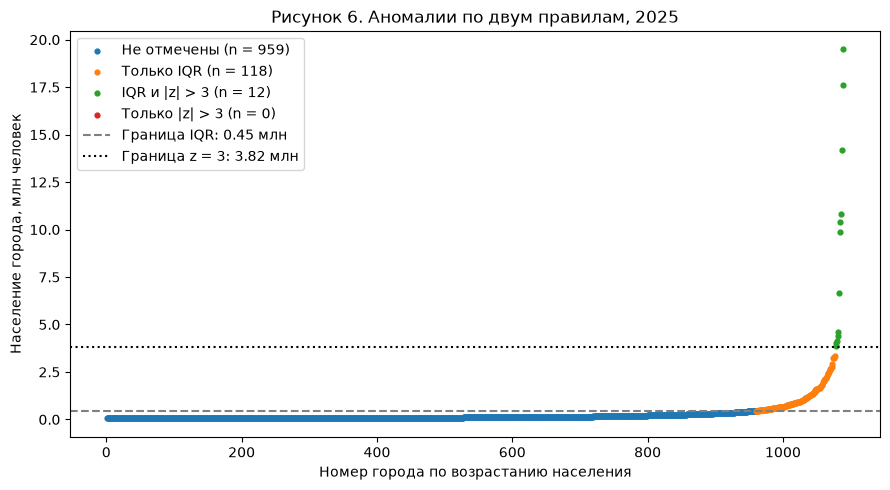

In [20]:
y = cross[eda.TARGET].to_numpy()
order_idx = np.argsort(y)
rank = np.arange(1, len(y) + 1)
y_sorted = y[order_idx] / 1e6

q1, q3 = np.quantile(y, [0.25, 0.75])
upper_iqr = (q3 + 1.5 * (q3 - q1)) / 1e6
upper_z = (y.mean() + 3 * y.std(ddof=0)) / 1e6

groups = [
    ("Не отмечены", ~(mask_iqr | mask_z)),
    ("Только IQR", mask_iqr & ~mask_z),
    ("IQR и |z| > 3", mask_iqr & mask_z),
    ("Только |z| > 3", mask_z & ~mask_iqr),
]

fig, ax = plt.subplots(figsize=(9, 5))
for label, m in groups:
    ms = m[order_idx]
    ax.scatter(rank[ms], y_sorted[ms], s=12, label=f"{label} (n = {int(m.sum())})")
ax.axhline(upper_iqr, linestyle="--", color="gray", label=f"Граница IQR: {upper_iqr:.2f} млн")
ax.axhline(upper_z, linestyle=":", color="black", label=f"Граница z = 3: {upper_z:.2f} млн")
ax.set_xlabel("Номер города по возрастанию населения")
ax.set_ylabel("Население города, млн человек")
ax.set_title("Рисунок 6. Аномалии по двум правилам, 2025")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "06_anomalies.png", dpi=150)
plt.show()

**Наблюдение 6.** Из 1089 городов 959 не отмечены, 118 отмечены только по IQR (выше границы 0,45 млн), 12 отмечены обоими правилами (выше 3,82 млн). Городов, отмеченных только по |z| > 3, нет. Нижняя граница IQR отрицательна, поэтому снизу аномалий нет.

In [21]:
import os
import platform
import zipfile

import matplotlib

tables = PLOTS / "tables"
tables.mkdir(exist_ok=True)

pd.Series(eda.describe_target(cross[eda.TARGET]), name="Значение").to_csv(
    tables / "table1.csv", encoding="utf-8-sig"
)
eda.period_table(long).to_csv(tables / "table2.csv", index=False, encoding="utf-8-sig")
eda.group_table(cross).to_csv(tables / "table3.csv", index=False, encoding="utf-8-sig")
t4.to_csv(tables / "table4.csv", index=False, encoding="utf-8-sig")
t5 = eda.benchmark_mean(long[eda.TARGET].to_numpy())
t5.to_csv(tables / "table5.csv", index=False, encoding="utf-8-sig")

versions = "\n".join(
    [
        f"python {platform.python_version()}",
        f"numpy {np.__version__}",
        f"pandas {pd.__version__}",
        f"matplotlib {matplotlib.__version__}",
        f"os {platform.platform()}",
        f"processor {platform.processor()}",
        f"cpu_count {os.cpu_count()}",
    ]
)
(tables / "versions.txt").write_text(versions, encoding="utf-8")

archive = Path("..") / "report_pack.zip"
files = sorted(PLOTS.glob("0*.png")) + sorted(tables.glob("*"))
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as pack:
    for item in files:
        pack.write(item, arcname=item.name)

print(t5.to_string(index=False))
print("\nв архиве:", [item.name for item in files])
print("размер архива, КБ:", round(archive.stat().st_size / 1024, 1))

                Способ  Медиана времени, с  Значение метрики
           Цикл Python            0.000879     262511.321392
                 numpy            0.000024     262511.321392
Отношение цикл / numpy           36.189298               NaN
        Число значений        13068.000000               NaN

в архиве: ['01_hist.png', '02_by_country.png', '03_series.png', '04_median_by_country.png', '05_heatmap.png', '06_anomalies.png', 'table1.csv', 'table2.csv', 'table3.csv', 'table4.csv', 'table5.csv', 'versions.txt']
размер архива, КБ: 346.2


In [22]:
for line in (Path("..") / "DATASET.md").read_text(encoding="utf-8").splitlines():
    if any(word in line.lower() for word in ("2030", "projection", "прогноз", "модел")):
        print(line[:300])